# Method bench 3: RGB combinations, and the best grey set-up against the best RGB set-up

**Best grey** (highest 21-seed gain vs production in Phase G, single arm or factorial cell): `B1p EM-Bayes pooled`.
**Best RGB** (same rule in Phase R): `COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile`.
**RGB minus grey** on the roads both assess: -0.60 [-2.22, +0.69] points (21 seeds, 3 × 3 block bootstrap; source:
`evidence/pilot_scripts/method_bench_3/bench3r_numbers.json`, key `grey_vs_rgb`). **R0 vs production:** -0.90 [-1.76, -0.28] points.

Below: the Phase R forest plots and interactions, the decision table, then the two best set-ups side by side on the same
tiles, with **error crops** where their calls disagree.

In [1]:
import sys, json
sys.path.insert(0, '../../evidence/pilot_scripts/method_bench_3')
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 70
import nbviz as V
num = V.numbers('R')
kept = V.kept_table('R')
tiles = json.loads((V.NB / 'R_tiles.json').read_text())
print('tiles:', tiles['chosen'])

tiles: [['thin cloud', '0_13_5'], ['thick cloud', '0_11_4'], ['clear', '0_15_8'], ['flooded', '2_20_58'], ['smoke tile', '2_23_44'], ['smoke tile', '2_19_55']]


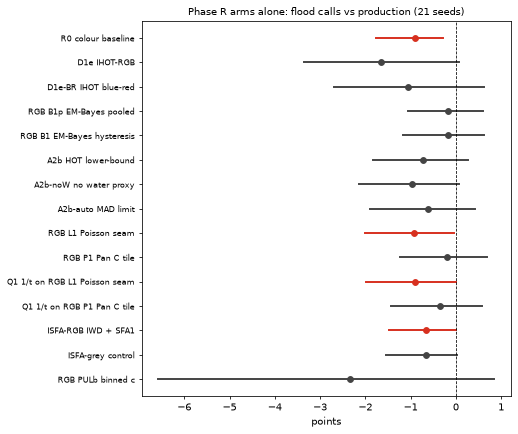

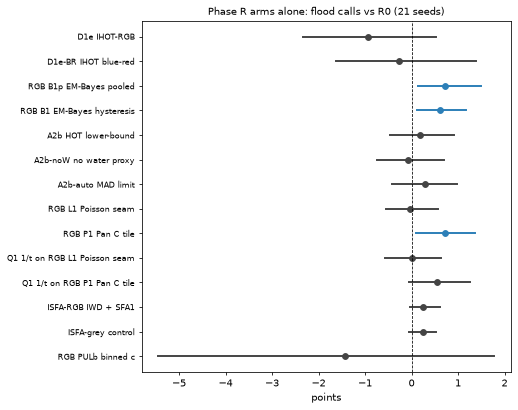

In [2]:
rows = [(n, 100 * r['seeds']['mean_gain'], 100 * r['seeds']['ci'][0], 100 * r['seeds']['ci'][1]) for n, r in num['flood'].items()]
V.forest(rows, 'Phase R arms alone: flood calls vs production (21 seeds)', 'points')
rows = [(n, 100 * r['vs_base']['seeds']['mean_gain'], 100 * r['vs_base']['seeds']['ci'][0], 100 * r['vs_base']['seeds']['ci'][1])
        for n, r in num['flood'].items() if 'vs_base' in r]
V.forest(rows, 'Phase R arms alone: flood calls vs R0 (21 seeds)', 'points')

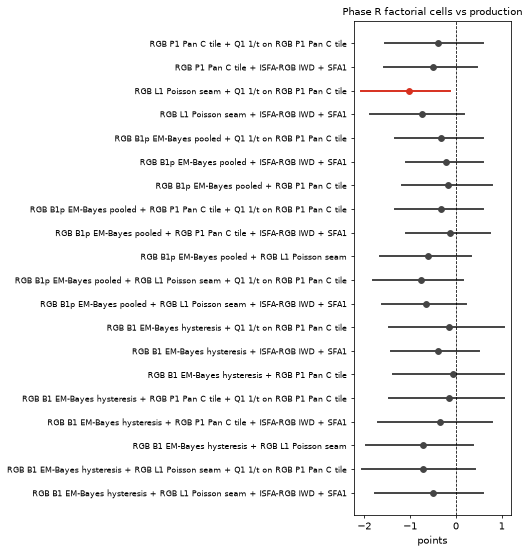

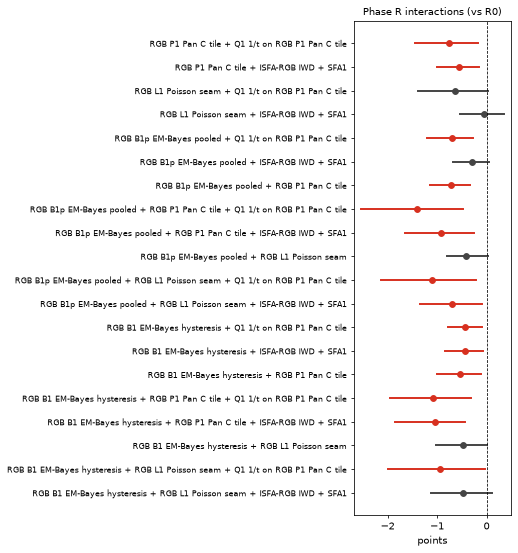

In [3]:
rows = [(n.replace('COMBO R ', ''), 100 * r['mean_gain'], 100 * r['ci'][0], 100 * r['ci'][1]) for n, r in num.get('combo', {}).items()]
if rows: V.forest(rows, 'Phase R factorial cells vs production', 'points')
rows = [(n.replace('COMBO R ', ''), 100 * r['interaction_vs_R0'], 100 * r['interaction_ci'][0], 100 * r['interaction_ci'][1]) for n, r in num.get('combo', {}).items()]
if rows: V.forest(rows, 'Phase R interactions (vs R0)', 'points')

In [4]:
pd.set_option('display.max_colwidth', 200)
pd.DataFrame(json.loads((V.HERE / 'bench3_decisions.json').read_text()).get('phase_R', []))

,arm,decision,evidence
0,R0 colour baseline,DROP,"harms: flood -0.90 [-1.76, -0.28] pts (1 seeds better, 19 worse)"
1,D1e IHOT-RGB,DROP,"no help: flood -1.66 [-3.35, +0.07] pts (0 seeds better, 21 worse); 29 roads added, 142 removed; accuracy on added roads 0.680 [0.288, 0.897]; vs R0 -0.94 [-2.34, +0.52] (3 better)"
2,D1e-BR IHOT blue-red,DROP,"no help: flood -1.06 [-2.70, +0.62] pts (0 seeds better, 20 worse); 26 roads added, 174 removed; accuracy on added roads 0.674 [0.214, 0.909]; vs R0 -0.27 [-1.62, +1.38] (5 better)"
3,RGB B1p EM-Bayes pooled,MAYBE,"helps vs R0 (interval above 0), not vs production: flood -0.17 [-1.06, +0.60] pts (7 seeds better, 14 worse); 56 roads added, 0 removed; accuracy on added roads 0.730 [0.545, 0.857]; vs R0 colour ..."
4,RGB B1 EM-Bayes hysteresis,MAYBE,"helps vs R0 (interval above 0), not vs production: flood -0.18 [-1.18, +0.61] pts (6 seeds better, 14 worse); 31 roads added, 26 removed; accuracy on added roads 0.693 [0.449, 0.875]; vs R0 colour..."
5,A2b HOT lower-bound,DROP,"no help: Ida primary vs C0 +0.0141 [-0.0010, +0.0311] (46 tiles), guard 2.23 (fails); flood -0.72 [-1.83, +0.27] pts (1 seeds better, 20 worse); vs R0 colour baseline +0.18 [-0.47, +0.91]"
6,A2b-noW no water proxy,DROP,"no help: Ida primary vs C0 +0.0090 [-0.0057, +0.0222] (47 tiles), guard 2.80 (fails); flood -0.98 [-2.15, +0.08] pts (0 seeds better, 19 worse); vs R0 colour baseline -0.08 [-0.73, +0.71]"
7,A2b-auto MAD limit,DROP,"harms: Ida primary vs C0 +0.0142 [+0.0061, +0.0221] (35 tiles), guard 0.37 (ok); flood -0.61 [-1.90, +0.41] pts (4 seeds better, 16 worse); vs R0 colour baseline +0.29 [-0.42, +0.98]"
8,RGB L1 Poisson seam,DROP,"harms: Ida primary vs C0 -0.0057 [-0.0151, +0.0025] (73 tiles), guard 0.22 (ok); flood -0.93 [-2.01, -0.05] pts (0 seeds better, 20 worse); vs R0 colour baseline -0.03 [-0.54, +0.57]"
9,RGB P1 Pan C tile,MAYBE,"helps vs R0 (interval above 0), not vs production: Ida primary vs C0 -0.0084 [-0.0133, -0.0035] (73 tiles), guard 0.70 (ok); flood -0.19 [-1.24, +0.69] pts (5 seeds better, 14 worse); vs R0 colour..."


## `B1p EM-Bayes pooled` (grey) against `COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile` (RGB) on the same tiles
Left: the grey set-up's calls; right: the RGB set-up's calls. Below each tile: crops (about 100 m) around the roads where the two disagree, with the label.

thin cloud: 0_13_5


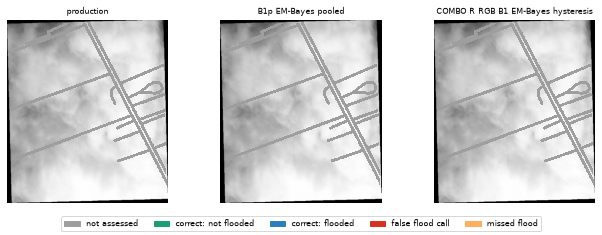

0 roads assessed by both set-ups where their seed-662 calls disagree


In [5]:
d = V.load('R', '0_13_5')
print('thin cloud: 0_13_5')
V.panel_calls(d, ['production', 'B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'], kept, phase='R')
rd = d['roads']
cg, cr = rd.get('call662|B1p EM-Bayes pooled'), rd.get('call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile')
if cg is not None and cr is not None:
    ka = [bool(kept[V.KEPT_ALIAS.get(c, c)].iloc[int(i)]) if V.KEPT_ALIAS.get(c, c) in kept.columns else True
          for c in ('B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile') for i in rd.road_row]
    n = len(rd)
    both = np.array(ka[:n]) & np.array(ka[n:])
    dis = rd[(cg != cr) & both]
    print(len(dis), 'roads assessed by both set-ups where their seed-662 calls disagree')
    for _, x in dis.head(4).iterrows():
        ys, xs = np.nonzero(d['strip'] == x.strip_id)
        cy, cx = int(ys.mean()), int(xs.mean()); h = 100
        sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
        fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
        ax[0].imshow(d['before_rgb'][sl]); ax[0].set_title('before', fontsize=8)
        ax[1].imshow(d['after_rgb'][sl]); ax[1].set_title('after', fontsize=8)
        ax[2].imshow(d['after_rgb'][sl]); ax[2].contour(d['strip'][sl] == x.strip_id, colors='yellow', linewidths=0.8)
        ax[2].set_title(f"road {x.road_id}: label {'flooded' if x.flooded else 'not flooded'}; grey calls {int(x['call662|B1p EM-Bayes pooled'])}, RGB calls {int(x['call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'])}", fontsize=7)
        for a in ax: a.axis('off')
        plt.tight_layout(); plt.show()

thick cloud: 0_11_4


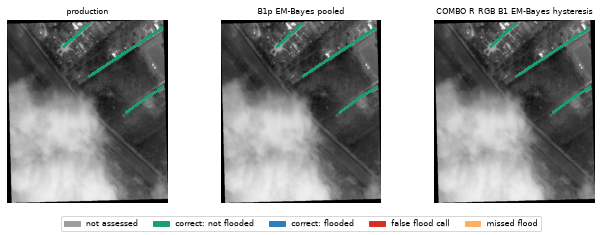

0 roads assessed by both set-ups where their seed-662 calls disagree


In [6]:
d = V.load('R', '0_11_4')
print('thick cloud: 0_11_4')
V.panel_calls(d, ['production', 'B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'], kept, phase='R')
rd = d['roads']
cg, cr = rd.get('call662|B1p EM-Bayes pooled'), rd.get('call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile')
if cg is not None and cr is not None:
    ka = [bool(kept[V.KEPT_ALIAS.get(c, c)].iloc[int(i)]) if V.KEPT_ALIAS.get(c, c) in kept.columns else True
          for c in ('B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile') for i in rd.road_row]
    n = len(rd)
    both = np.array(ka[:n]) & np.array(ka[n:])
    dis = rd[(cg != cr) & both]
    print(len(dis), 'roads assessed by both set-ups where their seed-662 calls disagree')
    for _, x in dis.head(4).iterrows():
        ys, xs = np.nonzero(d['strip'] == x.strip_id)
        cy, cx = int(ys.mean()), int(xs.mean()); h = 100
        sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
        fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
        ax[0].imshow(d['before_rgb'][sl]); ax[0].set_title('before', fontsize=8)
        ax[1].imshow(d['after_rgb'][sl]); ax[1].set_title('after', fontsize=8)
        ax[2].imshow(d['after_rgb'][sl]); ax[2].contour(d['strip'][sl] == x.strip_id, colors='yellow', linewidths=0.8)
        ax[2].set_title(f"road {x.road_id}: label {'flooded' if x.flooded else 'not flooded'}; grey calls {int(x['call662|B1p EM-Bayes pooled'])}, RGB calls {int(x['call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'])}", fontsize=7)
        for a in ax: a.axis('off')
        plt.tight_layout(); plt.show()

clear: 0_15_8


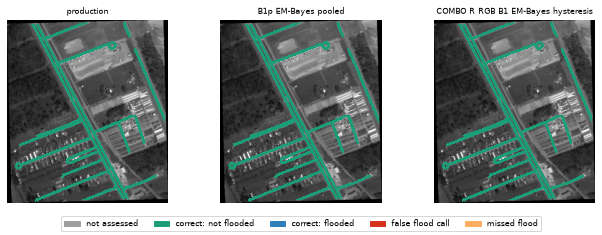

0 roads assessed by both set-ups where their seed-662 calls disagree


In [7]:
d = V.load('R', '0_15_8')
print('clear: 0_15_8')
V.panel_calls(d, ['production', 'B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'], kept, phase='R')
rd = d['roads']
cg, cr = rd.get('call662|B1p EM-Bayes pooled'), rd.get('call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile')
if cg is not None and cr is not None:
    ka = [bool(kept[V.KEPT_ALIAS.get(c, c)].iloc[int(i)]) if V.KEPT_ALIAS.get(c, c) in kept.columns else True
          for c in ('B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile') for i in rd.road_row]
    n = len(rd)
    both = np.array(ka[:n]) & np.array(ka[n:])
    dis = rd[(cg != cr) & both]
    print(len(dis), 'roads assessed by both set-ups where their seed-662 calls disagree')
    for _, x in dis.head(4).iterrows():
        ys, xs = np.nonzero(d['strip'] == x.strip_id)
        cy, cx = int(ys.mean()), int(xs.mean()); h = 100
        sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
        fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
        ax[0].imshow(d['before_rgb'][sl]); ax[0].set_title('before', fontsize=8)
        ax[1].imshow(d['after_rgb'][sl]); ax[1].set_title('after', fontsize=8)
        ax[2].imshow(d['after_rgb'][sl]); ax[2].contour(d['strip'][sl] == x.strip_id, colors='yellow', linewidths=0.8)
        ax[2].set_title(f"road {x.road_id}: label {'flooded' if x.flooded else 'not flooded'}; grey calls {int(x['call662|B1p EM-Bayes pooled'])}, RGB calls {int(x['call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'])}", fontsize=7)
        for a in ax: a.axis('off')
        plt.tight_layout(); plt.show()

flooded: 2_20_58


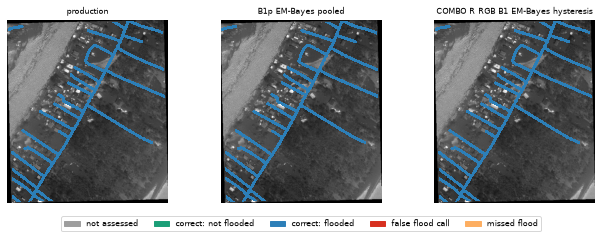

0 roads assessed by both set-ups where their seed-662 calls disagree


In [8]:
d = V.load('R', '2_20_58')
print('flooded: 2_20_58')
V.panel_calls(d, ['production', 'B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'], kept, phase='R')
rd = d['roads']
cg, cr = rd.get('call662|B1p EM-Bayes pooled'), rd.get('call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile')
if cg is not None and cr is not None:
    ka = [bool(kept[V.KEPT_ALIAS.get(c, c)].iloc[int(i)]) if V.KEPT_ALIAS.get(c, c) in kept.columns else True
          for c in ('B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile') for i in rd.road_row]
    n = len(rd)
    both = np.array(ka[:n]) & np.array(ka[n:])
    dis = rd[(cg != cr) & both]
    print(len(dis), 'roads assessed by both set-ups where their seed-662 calls disagree')
    for _, x in dis.head(4).iterrows():
        ys, xs = np.nonzero(d['strip'] == x.strip_id)
        cy, cx = int(ys.mean()), int(xs.mean()); h = 100
        sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
        fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
        ax[0].imshow(d['before_rgb'][sl]); ax[0].set_title('before', fontsize=8)
        ax[1].imshow(d['after_rgb'][sl]); ax[1].set_title('after', fontsize=8)
        ax[2].imshow(d['after_rgb'][sl]); ax[2].contour(d['strip'][sl] == x.strip_id, colors='yellow', linewidths=0.8)
        ax[2].set_title(f"road {x.road_id}: label {'flooded' if x.flooded else 'not flooded'}; grey calls {int(x['call662|B1p EM-Bayes pooled'])}, RGB calls {int(x['call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'])}", fontsize=7)
        for a in ax: a.axis('off')
        plt.tight_layout(); plt.show()

smoke tile: 2_23_44


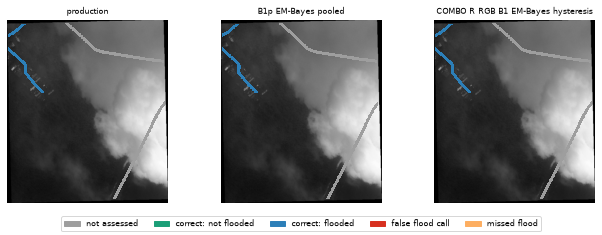

0 roads assessed by both set-ups where their seed-662 calls disagree


In [9]:
d = V.load('R', '2_23_44')
print('smoke tile: 2_23_44')
V.panel_calls(d, ['production', 'B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'], kept, phase='R')
rd = d['roads']
cg, cr = rd.get('call662|B1p EM-Bayes pooled'), rd.get('call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile')
if cg is not None and cr is not None:
    ka = [bool(kept[V.KEPT_ALIAS.get(c, c)].iloc[int(i)]) if V.KEPT_ALIAS.get(c, c) in kept.columns else True
          for c in ('B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile') for i in rd.road_row]
    n = len(rd)
    both = np.array(ka[:n]) & np.array(ka[n:])
    dis = rd[(cg != cr) & both]
    print(len(dis), 'roads assessed by both set-ups where their seed-662 calls disagree')
    for _, x in dis.head(4).iterrows():
        ys, xs = np.nonzero(d['strip'] == x.strip_id)
        cy, cx = int(ys.mean()), int(xs.mean()); h = 100
        sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
        fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
        ax[0].imshow(d['before_rgb'][sl]); ax[0].set_title('before', fontsize=8)
        ax[1].imshow(d['after_rgb'][sl]); ax[1].set_title('after', fontsize=8)
        ax[2].imshow(d['after_rgb'][sl]); ax[2].contour(d['strip'][sl] == x.strip_id, colors='yellow', linewidths=0.8)
        ax[2].set_title(f"road {x.road_id}: label {'flooded' if x.flooded else 'not flooded'}; grey calls {int(x['call662|B1p EM-Bayes pooled'])}, RGB calls {int(x['call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'])}", fontsize=7)
        for a in ax: a.axis('off')
        plt.tight_layout(); plt.show()

smoke tile: 2_19_55


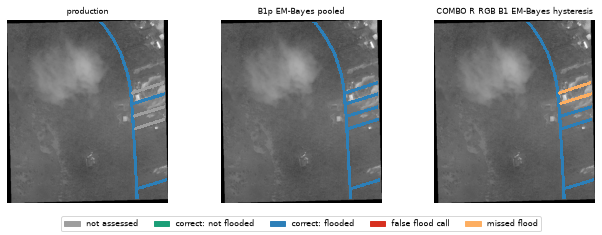

2 roads assessed by both set-ups where their seed-662 calls disagree


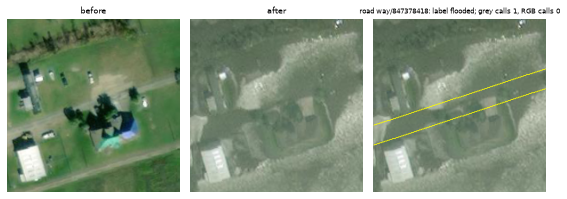

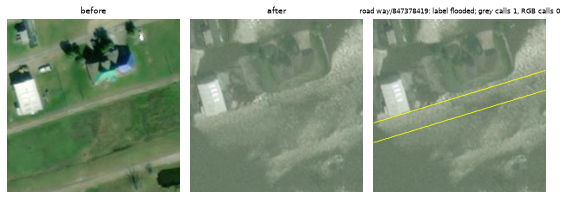

In [10]:
d = V.load('R', '2_19_55')
print('smoke tile: 2_19_55')
V.panel_calls(d, ['production', 'B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'], kept, phase='R')
rd = d['roads']
cg, cr = rd.get('call662|B1p EM-Bayes pooled'), rd.get('call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile')
if cg is not None and cr is not None:
    ka = [bool(kept[V.KEPT_ALIAS.get(c, c)].iloc[int(i)]) if V.KEPT_ALIAS.get(c, c) in kept.columns else True
          for c in ('B1p EM-Bayes pooled', 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile') for i in rd.road_row]
    n = len(rd)
    both = np.array(ka[:n]) & np.array(ka[n:])
    dis = rd[(cg != cr) & both]
    print(len(dis), 'roads assessed by both set-ups where their seed-662 calls disagree')
    for _, x in dis.head(4).iterrows():
        ys, xs = np.nonzero(d['strip'] == x.strip_id)
        cy, cx = int(ys.mean()), int(xs.mean()); h = 100
        sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
        fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
        ax[0].imshow(d['before_rgb'][sl]); ax[0].set_title('before', fontsize=8)
        ax[1].imshow(d['after_rgb'][sl]); ax[1].set_title('after', fontsize=8)
        ax[2].imshow(d['after_rgb'][sl]); ax[2].contour(d['strip'][sl] == x.strip_id, colors='yellow', linewidths=0.8)
        ax[2].set_title(f"road {x.road_id}: label {'flooded' if x.flooded else 'not flooded'}; grey calls {int(x['call662|B1p EM-Bayes pooled'])}, RGB calls {int(x['call662|COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'])}", fontsize=7)
        for a in ax: a.axis('off')
        plt.tight_layout(); plt.show()

## Error crops across all development tiles
Roads assessed by both set-ups where their **21-seed majority** calls differ (calls: `BIG/bench3_flood_calls.npz`, `BIG/bench3r_flood_calls.npz`; labels: SN8 published). Up to 8 roads, ordered by tile; each crop is ~100 m around the road (yellow outline). Only these tiles' images are read (development tiles).

39 roads (of 800 assessed by both) where the majority calls differ; 23 of them the grey set-up is right, 16 the RGB set-up


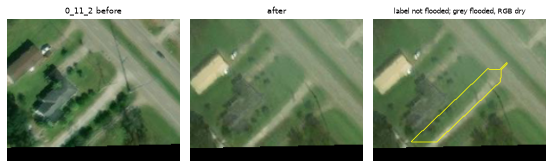

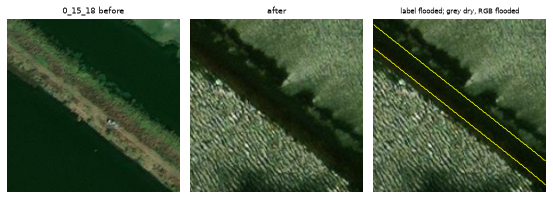

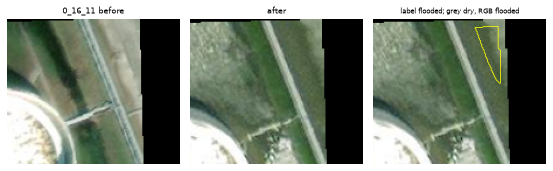

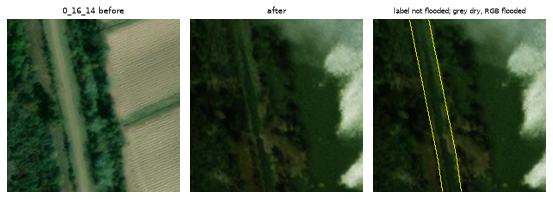

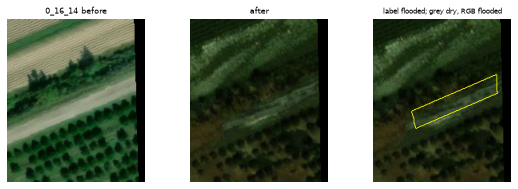

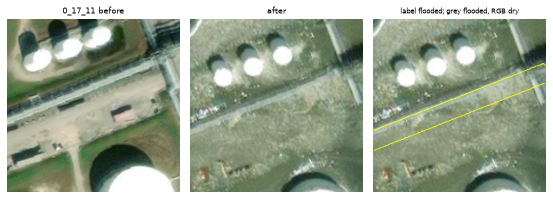

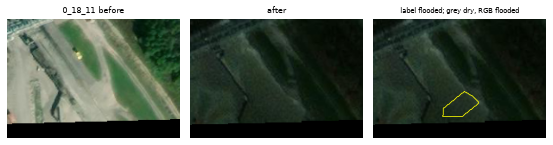

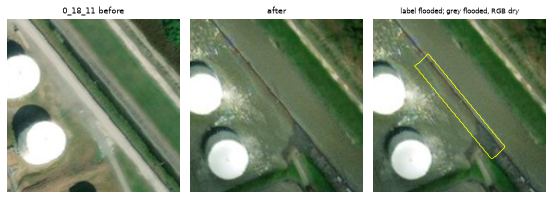

In [11]:
import sys
sys.path.append('/Users/jusrogers/Masters/GGS662/ProjectBranch/ClaudeFunctions')
zg, zr = np.load(V.BIG / 'bench3_flood_calls.npz'), np.load(V.BIG / 'bench3r_flood_calls.npz')
cg = np.stack([zg[f'B1p EM-Bayes pooled__{s}'] for s in V.SEEDS]); cr = np.stack([zr[f'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile__{s}'] for s in V.SEEDS])
mg, mr = (cg == 1).mean(0) > 0.5, (cr == 1).mean(0) > 0.5
kg = kept[V.KEPT_ALIAS.get('B1p EM-Bayes pooled', 'B1p EM-Bayes pooled')].to_numpy().astype(bool) if V.KEPT_ALIAS.get('B1p EM-Bayes pooled', 'B1p EM-Bayes pooled') in kept.columns else kept['production (refit)'].to_numpy().astype(bool)
kr = kept['COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile'].to_numpy().astype(bool) if 'COMBO R RGB B1 EM-Bayes hysteresis + RGB P1 Pan C tile' in kept.columns else kept['production (refit)'].to_numpy().astype(bool)
idx = np.flatnonzero(kg & kr & (mg != mr))
y = kept.flooded.to_numpy()
print(len(idx), 'roads (of', int((kg & kr).sum()), 'assessed by both) where the majority calls differ;',
      int((mg[idx] == y[idx]).sum()), 'of them the grey set-up is right,', int((mr[idx] == y[idx]).sum()), 'the RGB set-up')
from sn8_clouds import _tile
from sn8_cloudspot import _strip
from sn8_lines import road_band
for i in idx[:8]:
    tid, rid = kept.tile_id.iloc[i], kept.road_id.iloc[i]
    p, b, a, v = _tile(tid)
    strip, roads, n, cpx = _strip(tid, p, v, road_band())
    ks = [k + 1 for k in range(n) if roads[k + 1]['road_id'] == rid]
    if not ks: continue
    m = strip == ks[0]
    ys, xs = np.nonzero(m); cy, cx = int(ys.mean()), int(xs.mean()); h = 100
    sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
    fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
    ax[0].imshow(p['before_rgb'][sl]); ax[0].set_title(f'{tid} before', fontsize=8)
    ax[1].imshow(p['after_rgb'][sl]); ax[1].set_title('after', fontsize=8)
    ax[2].imshow(p['after_rgb'][sl]); ax[2].contour(m[sl], colors='yellow', linewidths=0.8)
    ax[2].set_title(f"label {'flooded' if y[i] else 'not flooded'}; grey {'flooded' if mg[i] else 'dry'}, RGB {'flooded' if mr[i] else 'dry'}", fontsize=7)
    for q in ax: q.axis('off')
    plt.tight_layout(); plt.show()